# Momentum Factor and Factor Momentum

Momentum describes the tendency for recent relative winners to continue outperforming recent losers over intermediate horizons. In this notebook, I examine the pattern using published stock-momentum portfolios, then construct momentum strategies across factor returns. I use the examples to explain the methods, without claiming to replicate a single paper.

The comparison uses returns observed before month $t$ to study returns earned in month $t$.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
sys.path.insert(0, str(ROOT / "src"))
from factor_asset_pricing.french_data import load_french, sample_coverage
RAW = ROOT / "data/raw/french"
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from factor_asset_pricing.asset_pricing_tests import (
    factor_regressions,
    grs_test,
    performance_summary,
    sharpe_ratio,
    pricing_error_summary,
    time_series_regression,
)
from factor_asset_pricing.factors import fama_french_2x3_factor
from factor_asset_pricing.momentum import (
    conditional_future_returns,
    factor_momentum,
    momentum_signal,
)

plt.style.use("seaborn-v0_8-whitegrid")
pd.options.display.float_format = "{:,.3f}".format

factors = load_french("ff5", RAW).loc["1963-07":"2024-12"]
assert len(factors) == 738 and not factors.isna().any().any()
factors = factors[["MKT", "SMB", "HML", "RMW", "CMA"]]
risk_free = load_french("ff3", RAW)["RF"].loc[:"2024-12"]
# RF covers the full 1951–2024 long-only decile sample, FF5 starts later.
french_umd = load_french("momentum", RAW)["MOM"].loc[:"2024-12"].rename("French UMD")
display(sample_coverage(factors))


,start,end,observations,missing
MKT,1963-07-01 00:00:00,2024-12-01 00:00:00,738,0
SMB,1963-07-01 00:00:00,2024-12-01 00:00:00,738,0
HML,1963-07-01 00:00:00,2024-12-01 00:00:00,738,0
RMW,1963-07-01 00:00:00,2024-12-01 00:00:00,738,0
CMA,1963-07-01 00:00:00,2024-12-01 00:00:00,738,0


## 1. The momentum effect

Momentum uses past returns to form positions for the next holding period. In the asset-pricing literature, we work with two forms of momentum. **Cross-sectional momentum** buys recent relative winners and sells recent relative losers. **Time-series momentum** takes a long or short position according to each investment's own past return. Both use return history, but they make different comparisons. Both types are interesting and have shown robustness in the literature. In particular, cross-sectional momentum has been studied across many asset classes.

In addition, the horizon matters for the momentum effect. In general, returns can reverse over short periods, continue over intermediate periods, and reverse again over longer periods. These are some of the stylized facts documented across the many studies in the asset-pricing literature. Skipping the latest month in the stock-momentum signal helps separate the intermediate pattern from very short-run effects.


## 2. The momentum factor: Cross-sectional stock momentum

Cross-sectional momentum takes long positions in recent winners and short positions in recent losers. Because of its robustness across assets, cross-sectional momentum has become quite well known, especially given its intuitive rule of thumb. In the following, I construct the cross-sectional momentum spread from published portfolios and apply the simple asset-pricing tests from the previous notebooks.

The stock signal follows the conventional 12–2 rule. For a return earned in month $t$, it compounds the eleven monthly returns from $t-12$ through $t-2$:

$$MOM_{i,t}^{12-2}=\prod_{k=2}^{12}(1+R_{i,t-k})-1.$$

The latest month is skipped to separate intermediate momentum from very short-run effects. French forms portfolios monthly using market equity from the end of the previous month. The NYSE median divides small and big stocks, while NYSE momentum percentiles at 30% and 70% divide losers, neutral stocks, and winners.

I use the six published value-weighted portfolio returns to construct UMD:

$$UMD_t=\tfrac12(SmallHigh_t+BigHigh_t)-\tfrac12(SmallLow_t+BigLow_t).$$

The high and low labels refer to prior returns. Each side gives equal weight to small and big portfolios, while the stocks inside each portfolio are value weighted. A positive UMD return means the winner leg outperformed the loser leg. No further risk-free return is subtracted.

This reproduces the factor-combination step, not the underlying security assignments. Rebuilding those assignments would require CRSP returns, prices, market equity, and French's eligibility rules. The source is `6_Portfolios_ME_Prior_12_2_CSV.zip` from the [official French download](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/6_Portfolios_ME_Prior_12_2_CSV.zip). Like the other original inputs, it is placed manually in `data/raw/french/` and left unchanged.

The ten published momentum deciles remain useful for illustrating the return pattern and testing the models, but P10 minus P1 is not the UMD factor used below. I keep January 1951–December 2024 for the portfolio histories and July 1963 onward for FF5 comparisons. Dates are consecutive monthly labels and returns are decimals.


### 2.1 Momentum deciles

I start with the ten published momentum deciles to see whether average returns rise with past performance. Alongside average monthly returns, I show FF5 alphas. The return panel uses January 1951–December 2024, while the alpha panel starts in July 1963 because FF5 begins later. Differences between the panels therefore reflect both benchmark adjustment and sample coverage. Error bars show approximate 95% intervals using Newey–West standard errors with 12 monthly lags.


In [2]:
momentum_deciles = load_french("momentum_deciles", RAW).loc["1951-01":"2024-12"]
size_momentum = load_french("momentum_size", RAW).loc["1951-01":"2024-12"]
assert len(size_momentum) == 888 and not size_momentum.isna().any().any()
assert not momentum_deciles.isna().any().any()

# Use the same 2×3 factor construction as the other Fama–French factors.
size_momentum_cells = size_momentum.rename_axis(columns="portfolio").reset_index().melt(
    id_vars="date", value_name="ret"
)
size_momentum_cells["prior_return_group"] = size_momentum_cells["portfolio"].map({
    "SmallLow": "Low", "SmallMiddle": "Middle", "SmallHigh": "High",
    "BigLow": "Low", "BigMiddle": "Middle", "BigHigh": "High",
})
size_momentum_cells["size_group"] = size_momentum_cells["portfolio"].str.extract(r"^(Small|Big)", expand=False)
umd_legs = fama_french_2x3_factor(
    size_momentum_cells, size_col="size_group", characteristic_col="prior_return_group",
    small="Small", big="Big", low="Low", middle="Middle", high="High", name="UMD",
).set_index("date")
constructed_umd = umd_legs["UMD"]
expected_umd = .5 * (size_momentum["SmallHigh"] + size_momentum["BigHigh"]
                     - size_momentum["SmallLow"] - size_momentum["BigLow"])
assert np.allclose(constructed_umd, expected_umd)
momentum_portfolios = momentum_deciles.rename(columns={f"P{i}": i for i in range(1, 11)}).rename_axis(columns="momentum_portfolio").reset_index().melt(id_vars="date", value_name="ret")


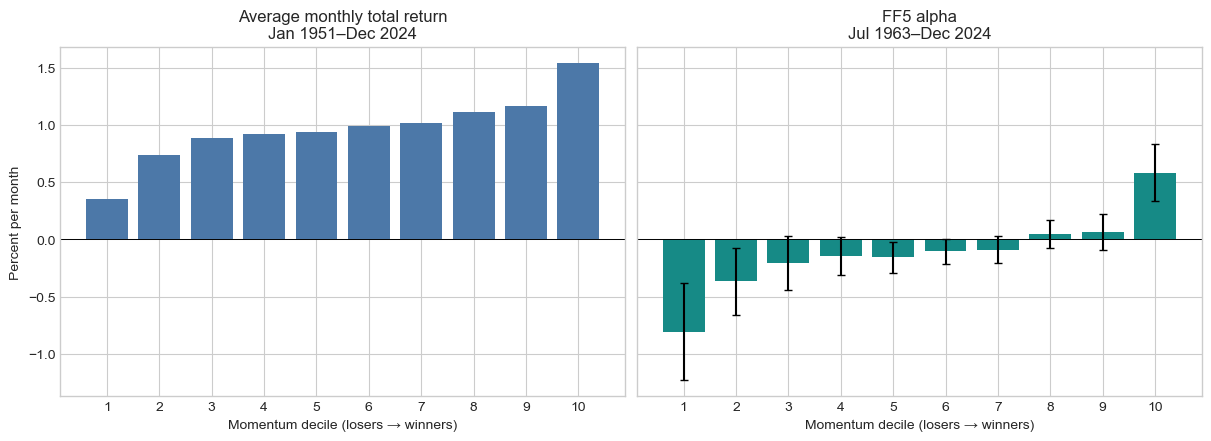

,FF5 alpha (% monthly),NW SE (% monthly),NW t(alpha),Months
asset,,,,
P1,-0.806,0.218,-3.704,738
P2,-0.365,0.150,-2.442,738
P3,-0.206,0.119,-1.729,738
P4,-0.144,0.084,-1.715,738
P5,-0.157,0.069,-2.292,738
P6,-0.105,0.055,-1.908,738
P7,-0.090,0.060,-1.499,738
P8,0.047,0.063,0.745,738
P9,0.064,0.081,0.791,738


In [3]:
decile_profile = 100 * momentum_portfolios.groupby("momentum_portfolio")["ret"].mean()
decile_alpha_sample = pd.concat([momentum_deciles, risk_free, factors], axis=1).dropna()
decile_excess = decile_alpha_sample[momentum_deciles.columns].sub(decile_alpha_sample["RF"], axis=0)
decile_ff5 = factor_regressions(decile_excess, decile_alpha_sample[factors.columns], cov_type="HAC", hac_lags=12)
assert decile_ff5["nobs"].eq(len(decile_alpha_sample)).all()
assert len(decile_alpha_sample) == 738

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), sharey=True, layout="constrained")
x = np.arange(1, 11)
return_dates = f"{momentum_deciles.index.min():%b %Y}–{momentum_deciles.index.max():%b %Y}"
alpha_dates = f"{decile_alpha_sample.index.min():%b %Y}–{decile_alpha_sample.index.max():%b %Y}"
axes[0].bar(x, decile_profile, color="#4C78A8")
axes[0].set(title=f"Average monthly total return\n{return_dates}", ylabel="Percent per month")
axes[1].bar(x, 100 * decile_ff5["alpha"], yerr=1.96 * 100 * decile_ff5["alpha_se"],
            capsize=3, color="#168A86")
axes[1].set(title=f"FF5 alpha\n{alpha_dates}")
for ax in axes:
    ax.axhline(0, color="black", linewidth=0.7)
    ax.set(xlabel="Momentum decile (losers → winners)", xticks=x)
plt.show()
display(decile_ff5[["alpha", "alpha_se", "alpha_t", "nobs"]].rename(
    columns={"alpha": "FF5 alpha (% monthly)", "alpha_se": "NW SE (% monthly)",
             "alpha_t": "NW t(alpha)", "nobs": "Months"}
).assign(**{"FF5 alpha (% monthly)": 100 * decile_ff5["alpha"],
            "NW SE (% monthly)": 100 * decile_ff5["alpha_se"]}))


The decile comparison separates the pattern in average returns from what remains after FF5 adjustment. It uses all ten groups, rather than only the two extremes. These deciles also serve as the test portfolios later in the notebook. The UMD factor used for spanning is constructed from the size-balanced 2×3 portfolios above, not by subtracting decile 1 from decile 10.


In [4]:
# Keep the French replication check without adding another empirical display.
validation_sample = pd.concat([constructed_umd, french_umd], axis=1).dropna()
validation_difference = validation_sample["UMD"] - validation_sample["French UMD"]
assert validation_difference.abs().max() <= 0.000151, "UMD differs by more than source rounding permits. Check source vintages."


### 2.2 Factor Spanning Tests: CAPM, FF3, and FF5

I apply the spanning test from [04](04_time_series_factor_regressions.ipynb) to my size-balanced 2×3 UMD construction, using CAPM, FF3, and FF5 as benchmarks:

$$UMD_t=\alpha+\boldsymbol\beta'\mathbf F_t+\varepsilon_t.$$

All three models use the same months, OLS coefficients, and Newey–West standard errors with 12 monthly lags. UMD is already a self-financing payoff. French UMD remains only a validation benchmark.

As in 04, the three-factor comparison uses SMB from the FF5 dataset. A significant alpha means that the selected benchmark does not explain UMD's average return in this sample, without identifying why the remaining premium exists.


In [5]:
models = {
    "CAPM": ["MKT"],
    "FF3": ["MKT", "SMB", "HML"],
    "FF5": ["MKT", "SMB", "HML", "RMW", "CMA"],
}
stock_model_sample = pd.concat([constructed_umd, factors], axis=1).dropna()
stock_model_rows = []
for model_name, regressors in models.items():
    fit = time_series_regression(stock_model_sample["UMD"], stock_model_sample[regressors], cov_type="HAC", hac_lags=12)
    row = {
        "Model": model_name,
        "Alpha (% monthly)": 100 * fit.params["const"],
        "NW t(alpha)": fit.tvalues["const"],
        "Adjusted R²": fit.rsquared_adj,
        "N": int(fit.nobs),
    }
    for factor in ["MKT", "SMB", "HML", "RMW", "CMA"]:
        row[f"β {factor}"] = fit.params.get(factor, np.nan)
        row[f"NW t(β {factor})"] = fit.tvalues.get(factor, np.nan)
    stock_model_rows.append(row)
stock_model_table = pd.DataFrame(stock_model_rows).set_index("Model")
stock_model_table

,Alpha (% monthly),NW t(alpha),Adjusted R²,N,β MKT,NW t(β MKT),β SMB,NW t(β SMB),β HML,NW t(β HML),β RMW,NW t(β RMW),β CMA,NW t(β CMA)
Model,,,,,,,,,,,,,,
CAPM,0.703,5.145,0.029,738,-0.164,-2.074,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
FF3,0.825,6.110,0.081,738,-0.203,-3.045,-0.028,-0.239,-0.332,-2.623,NaN,NaN,NaN,NaN
FF5,0.703,3.661,0.095,738,-0.162,-2.481,0.021,0.186,-0.494,-3.708,0.170,0.757,0.344,1.639


The constructed UMD retains statistically significant alpha in all three models. Its FF5 alpha is approximately 0.703% per month, with a Newey–West $t$-statistic of 3.661 and adjusted $R^2$ of 0.095. Market and value loadings are significantly negative ($t=-2.481$ and $t=-3.708$). The size loading is close to zero and insignificant ($t=0.186$), while profitability and investment loadings are positive but insignificant ($t=0.757$ and $t=1.639$).

The size-balanced construction therefore still produces average return that these static benchmark exposures do not explain in this sample. As in 04, significant alpha does not identify whether the source is mispricing, omitted risk, or changing exposures.


## 3. Factor momentum: momentum across factors

Ehsani and Linnainmaa (2022) argue that factor returns themselves exhibit continuation and that this common persistence is related to conventional stock momentum. Here, I examine the same basic pattern using the much smaller five-factor universe available here.

For each factor, the comparison is between current returns after positive and negative compounded returns over the preceding 12 months. UMD is excluded from the factor set, so any later relationship between factor momentum and UMD is not mechanical.
To build the table, I calculate each factor's compounded return over the previous 12 completed months. I then separate the following monthly returns according to whether that trailing return was positive or negative. The two averages are shown in percent per month, and their difference is in percentage points. The counts show how many months enter each group. The Newey–West statistic tests whether the difference is zero, using the same 12-lag inference convention as before. The common sample is July 1964–December 2024 after the signal warmup.


In [6]:
factor_continuation = conditional_future_returns(factors, lookback=12, skip=1)
difference_t = {}
for factor in factors:
    signal = momentum_signal(factors[factor], lookback=12, skip=1)
    sample = pd.concat([factors[factor].rename("return"), signal.rename("signal")], axis=1).dropna()
    sample["positive"] = sample["signal"].gt(0).astype(float)
    fit = time_series_regression(sample["return"], sample[["positive"]], cov_type="HAC", hac_lags=12)
    difference_t[factor] = fit.tvalues["positive"]
factor_continuation["NW t(difference)"] = pd.Series(difference_t)
factor_continuation[["after_negative", "after_positive", "difference"]] *= 100
factor_continuation

,after_negative,after_positive,difference,n_negative,n_positive,NW t(difference)
asset,,,,,,
MKT,0.350,0.665,0.314,204,522,0.721
SMB,-0.149,0.505,0.653,333,393,3.032
HML,0.015,0.435,0.420,286,440,1.663
RMW,0.076,0.388,0.312,227,499,1.624
CMA,0.081,0.361,0.279,288,438,1.879


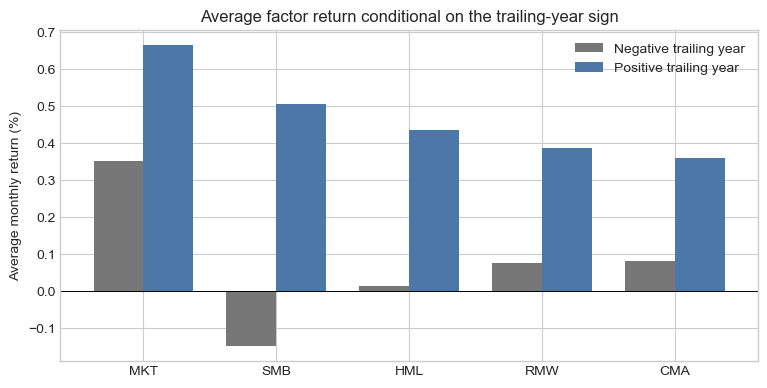

In [7]:
plot_data = factor_continuation[["after_negative", "after_positive"]].rename(columns={"after_negative": "Negative trailing year", "after_positive": "Positive trailing year"})
fig, ax = plt.subplots(figsize=(9, 4.3))
plot_data.plot.bar(ax=ax, color=["#777777", "#4C78A8"], width=0.75)
ax.axhline(0, color="black", linewidth=0.7)
ax.set(title="Average factor return conditional on the trailing-year sign", xlabel="", ylabel="Average monthly return (%)")
ax.tick_params(axis="x", rotation=0)
ax.legend(frameon=False)
plt.show()

The table shows higher subsequent average returns after a positive trailing year for all five factors. SMB has the largest difference: it earns 0.505% per month after positive trailing returns and −0.149% after negative trailing returns, a difference of 0.653 percentage points. Its Newey–West statistic is 3.032. The other four differences are positive but their statistics remain below 1.96 in absolute value, so only SMB rejects equal conditional means at the nominal 5% two-sided level. These are separate factor tests, without a multiple-testing adjustment.

The chart displays the same two averages for each factor. Every blue bar is above its grey counterpart, making the common direction of the differences visible. That does not mean every factor loses money after a negative trailing year: MKT, HML, RMW, and CMA still have positive average returns in those months. The chart therefore supports a conditional return difference, rather than a claim that shorting after every negative signal must be profitable.

Both displays show the original factor's next-month return, not the signed return of the momentum position. A short position reverses that payoff. The strategy constructed below evaluates the combined long and short positions directly. These five related equity factors provide a limited illustration, rather than broad evidence across independent strategies.


### 3.1 Constructing factor momentum

For the strategy, I recalculate the trailing 12-month signal at the end of each month, take a long position when it is positive and a short position when it is negative, and hold those positions during the next month. Each of the five factors receives an absolute weight of one fifth when its signal is nonzero:

$$FMOM_t=\frac{1}{N_t}\sum_{f\in\mathcal A_t}\operatorname{sign}(S_{f,t}^{(12)})F_{f,t}.$$

Here $\mathcal A_t$ contains the factors with both a valid signal and a current return, and $N_t$ is their number. Dividing by this count gives each available factor the same absolute weight when the signal is nonzero. Missing factor returns are never filled with zero. UMD is excluded from the factors used to construct FMOM, preventing its later relationship with stock momentum from becoming mechanical.

The signal $S_{f,t}^{(12)}=\prod_{j=1}^{12}(1+F_{f,t-j})-1$ compounds calendar months $t-12$ through $t-1$. Unlike the stock signal, it includes the latest completed month. The factor data must therefore have consecutive monthly observations. A positive signal gives a long position, a negative signal a short position, and a zero signal no position. For nonzero signals, absolute factor weights add to one, although signed weights need not add to zero. As in 03 and 06, factor-exposure weights do not measure the gross stock positions inside each factor.

A missing current return excludes a factor from the reported calculation. That uses data availability observed afterward, not information known when choosing the position. Positive- and negative-signal group means have separate denominators. Their difference is not generally the same portfolio as the sign-weighted FMOM above.

The signal here is compounded. Taking the sign of the sum or average of the 12 monthly returns would instead use an arithmetic signal. The sum and average have the same sign, but their sign can differ from the compounded return. This notebook retains the compounded signal used by the library.


### 3.2 Empirical implementation across factors

I use MKT, SMB, HML, RMW, and CMA as the five diversified traded return series. Each factor is held long following a positive trailing return and short following a negative trailing return. The positions are then averaged across the factors available that month. This is factor momentum in a narrow equity-factor universe, not evidence about a broad multi-asset time-series-momentum strategy.

In [8]:
horizon_strategies = pd.DataFrame({
    f"Formation {lookback}m": factor_momentum(factors, lookback=lookback, skip=1, name=f"Formation {lookback}m")
    for lookback in [1, 3, 6, 12]
}).dropna()
horizon_summary = performance_summary(horizon_strategies, hac_lags=12)
horizon_summary[["mean_annualized", "volatility_annualized", "sharpe", "mean_tstat", "skewness", "maximum_drawdown", "nobs"]]

,mean_annualized,volatility_annualized,sharpe,mean_tstat,skewness,maximum_drawdown,nobs
asset,,,,,,,
Formation 1m,0.040,0.059,0.681,5.863,0.156,-0.149,726
Formation 3m,0.029,0.063,0.456,4.121,0.368,-0.196,726
Formation 6m,0.028,0.059,0.465,3.627,0.310,-0.150,726
Formation 12m,0.034,0.058,0.578,5.311,0.213,-0.169,726


,mean_annualized,volatility_annualized,sharpe,mean_tstat,nobs
asset,,,,,
Equal-weighted factors,0.037,0.045,0.825,4.930,667
Positive-signal factors,0.061,0.067,0.899,6.972,667
Negative-signal factors,-0.002,0.095,-0.023,-0.187,667
Factor momentum,0.034,0.059,0.581,5.052,667


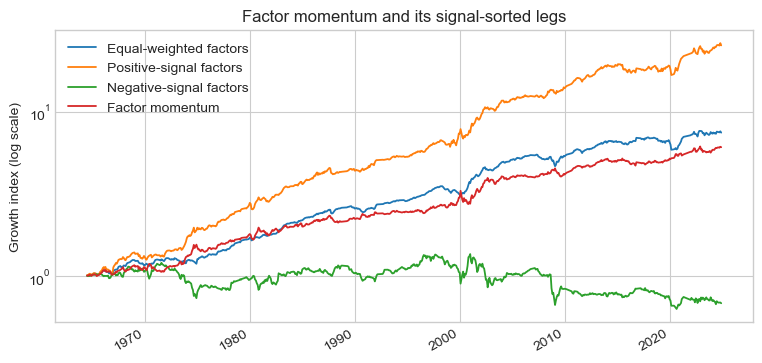

In [9]:
factor_signal = factors.apply(lambda series: momentum_signal(series, lookback=12, skip=1))
winner_factors = factors.where(factor_signal.gt(0)).mean(axis=1).rename("Positive-signal factors")
loser_factors = factors.where(factor_signal.lt(0)).mean(axis=1).rename("Negative-signal factors")
average_factor = factors.mean(axis=1).rename("Equal-weighted factors")
fmom = factor_momentum(factors, lookback=12, skip=1, name="Factor momentum")
factor_strategy_panel = pd.concat([average_factor, winner_factors, loser_factors, fmom], axis=1).dropna()
fmom_performance = performance_summary(factor_strategy_panel, hac_lags=12)
display(fmom_performance[["mean_annualized", "volatility_annualized", "sharpe", "mean_tstat", "nobs"]])

wealth = (1 + factor_strategy_panel).cumprod()
fig, ax = plt.subplots(figsize=(9, 4.3))
wealth.plot(ax=ax, linewidth=1.3)
ax.set_yscale("log")
ax.set(title="Factor momentum and its signal-sorted legs", xlabel="", ylabel="Growth index (log scale)")
ax.legend(frameon=False)
plt.show()

The formation-horizon comparison asks whether the result depends on how far back we look when deciding which side of each factor to hold. In the common sample used for the leg comparison, positive-signal factors earn 6.1% annualized, compared with −0.2% for negative-signal factors. The resulting factor-momentum strategy earns 3.4% annualized with a Sharpe ratio of 0.58. The 12-month implementation is retained as the main specification because it matches the factor-continuation question studied by Ehsani and Linnainmaa (2022).

### 3.3 Factor Spanning Tests for Factor Momentum

I then test factor momentum against the same nested CAPM, FF3, and FF5 benchmarks used for stock momentum. The common sample is fixed before any model is estimated.

In [10]:
fmom_model_sample = pd.concat([fmom.rename("FMOM"), factors], axis=1).dropna()
fmom_model_rows = []
for model_name, regressors in models.items():
    fit = time_series_regression(fmom_model_sample["FMOM"], fmom_model_sample[regressors], cov_type="HAC", hac_lags=12)
    row = {
        "Model": model_name,
        "Alpha (% monthly)": 100 * fit.params["const"],
        "NW t(alpha)": fit.tvalues["const"],
        "Adjusted R²": fit.rsquared_adj,
        "N": int(fit.nobs),
    }
    for factor in ["MKT", "SMB", "HML", "RMW", "CMA"]:
        row[f"β {factor}"] = fit.params.get(factor, np.nan)
    fmom_model_rows.append(row)
pd.DataFrame(fmom_model_rows).set_index("Model")

,Alpha (% monthly),NW t(alpha),Adjusted R²,N,β MKT,β SMB,β HML,β RMW,β CMA
Model,,,,,,,,,
CAPM,0.286,4.701,-0.001,726,-0.007,NaN,NaN,NaN,NaN
FF3,0.272,4.942,0.013,726,-0.018,0.071,0.020,NaN,NaN
FF5,0.235,3.528,0.046,726,0.003,0.073,-0.076,-0.013,0.216


These regressions test whether simply holding fixed exposures to the underlying factors explains factor momentum. It is not in this sample: the FF5 alpha is 0.235% per month with a Newey–West t-statistic of 3.528. The low adjusted $R^2$ also indicates that static contemporaneous loadings reproduce little of the strategy's time-series variation.

### 3.4 Pricing the stock-momentum deciles

Ehsani and Linnainmaa (2022) ask whether factor momentum explains the cross section of portfolios sorted on past stock returns. To explore that question here, I compare three models for the ten published French momentum deciles: FF5, FF5 augmented with UMD, and FF5 augmented with FMOM. I use the model-evaluation framework from [07](07_asset_pricing_model_evaluation.ipynb), with the same dates across models and the existing 12-lag Newey–West convention for individual alphas. GRS retains its separate assumptions from 07.

All ten deciles enter both the individual regressions and the GRS tests. UMD is formed from the separate size–momentum portfolios, so it is not exactly the decile P10-minus-P1 spread.


In [11]:
pricing_sample = pd.concat([momentum_deciles, risk_free, factors, constructed_umd, fmom.rename("FMOM")], axis=1).dropna()
test_assets = pricing_sample[momentum_deciles.columns].sub(pricing_sample["RF"], axis=0)
pricing_models = {
    "FF5": ["MKT", "SMB", "HML", "RMW", "CMA"],
    "FF5 + UMD": ["MKT", "SMB", "HML", "RMW", "CMA", "UMD"],
    "FF5 + FMOM": ["MKT", "SMB", "HML", "RMW", "CMA", "FMOM"],
}
pricing_results = {}
pricing_rows = []
spread = test_assets["P10"] - test_assets["P1"]
grs_assets = test_assets
for model_name, regressors in pricing_models.items():
    model_factors = pricing_sample[regressors]
    estimates = factor_regressions(test_assets, model_factors, cov_type="HAC", hac_lags=12)
    pricing_results[model_name] = estimates
    errors = pricing_error_summary(estimates)
    spread_fit = time_series_regression(spread, model_factors, cov_type="HAC", hac_lags=12)
    grs = grs_test(grs_assets, model_factors)
    pricing_rows.append({
        "Model": model_name,
        "Mean |alpha| (% monthly)": 100 * errors["mean_absolute_alpha"],
        "P10 − P1 alpha (% monthly)": 100 * spread_fit.params["const"],
        "NW t(spread alpha)": spread_fit.tvalues["const"],
        "Average adjusted R²": estimates["adjusted_r_squared"].mean(),
        "GRS test portfolios": len(grs_assets.columns),
        "GRS statistic": grs["statistic"],
        "GRS p-value": grs["pvalue"],
        "N": grs["nobs"],
    })
pricing_comparison = pd.DataFrame(pricing_rows).set_index("Model")
pricing_comparison

,Mean |alpha| (% monthly),P10 − P1 alpha (% monthly),NW t(spread alpha),Average adjusted R²,GRS test portfolios,GRS statistic,GRS p-value,N
Model,,,,,,,,
FF5,0.252,1.365,4.283,0.813,10,4.516,0.000,726
FF5 + UMD,0.124,0.321,3.050,0.903,10,3.433,0.000,726
FF5 + FMOM,0.124,0.781,3.214,0.853,10,3.257,0.000,726


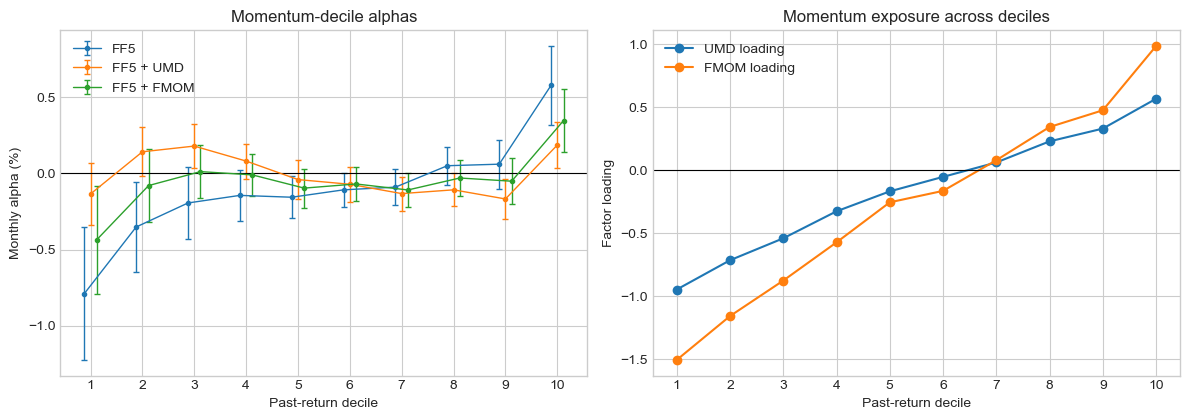

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
x = np.arange(1, 11)
for offset, (model_name, estimates) in zip([-0.12, 0, 0.12], pricing_results.items()):
    axes[0].errorbar(
        x + offset, 100 * estimates["alpha"], yerr=1.96 * 100 * estimates["alpha_se"],
        marker="o", markersize=3, linewidth=1, capsize=2, label=model_name,
    )
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set(title="Momentum-decile alphas", xlabel="Past-return decile", ylabel="Monthly alpha (%)", xticks=x)
axes[0].legend(frameon=False)
axes[1].plot(x, pricing_results["FF5 + UMD"]["beta_UMD"], marker="o", label="UMD loading")
axes[1].plot(x, pricing_results["FF5 + FMOM"]["beta_FMOM"], marker="o", label="FMOM loading")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set(title="Momentum exposure across deciles", xlabel="Past-return decile", ylabel="Factor loading", xticks=x)
axes[1].legend(frameon=False)
plt.tight_layout()
plt.show()

Both UMD and FMOM reduce the pricing errors left by FF5. Mean absolute alpha across the ten deciles falls from 0.252% per month to approximately 0.124% with either added factor. UMD reduces the P10-minus-P1 alpha from 1.365% to 0.321%, while adding FMOM leaves 0.781%. Both remaining spreads are significant, with Newey–West statistics of 3.050 and 3.214.

UMD uses the size-balanced 2×3 portfolios rather than the two extreme deciles, so the remaining P10-minus-P1 alpha is not forced to zero. All ten deciles enter the GRS tests, and all three models reject joint zero alpha at 5%. The loading panel shows how momentum exposures change across the deciles.

The constructed FMOM does not fully absorb the stock-momentum spread in this application. The narrow five-factor universe and selected sample remain important differences from the broader analysis in Ehsani and Linnainmaa (2022).


### 3.5 Stock and factor momentum spanning

Finally, I ask whether my size-balanced UMD and the internally constructed factor-momentum strategy each add average return beyond constant exposures to the other strategy and FF5:

$$UMD_t=\alpha+\boldsymbol\beta'FF5_t+\gamma FMOM_t+\varepsilon_t,$$

$$FMOM_t=\alpha+\boldsymbol\beta'FF5_t+\gamma UMD_t+\varepsilon_t.$$

Both regressions use exactly the same complete sample. Ehsani and Linnainmaa use a much broader factor universe and different source data, so our estimates are an application of their question rather than a replication of their headline result.

In [13]:
spanning_sample = pd.concat([constructed_umd, fmom.rename("FMOM"), factors], axis=1).dropna()
spanning_specs = {
    "UMD on FF5 + FMOM": ("UMD", ["MKT", "SMB", "HML", "RMW", "CMA", "FMOM"], "FMOM"),
    "FMOM on FF5 + UMD": ("FMOM", ["MKT", "SMB", "HML", "RMW", "CMA", "UMD"], "UMD"),
}
spanning_rows = []
for label, (dependent, regressors, momentum_regressor) in spanning_specs.items():
    fit = time_series_regression(spanning_sample[dependent], spanning_sample[regressors], cov_type="HAC", hac_lags=12)
    spanning_rows.append({
        "Regression": label,
        "Alpha (% monthly)": 100 * fit.params["const"],
        "NW t(alpha)": fit.tvalues["const"],
        "Momentum loading": fit.params[momentum_regressor],
        "NW t(loading)": fit.tvalues[momentum_regressor],
        "Adjusted R²": fit.rsquared_adj,
        "N": int(fit.nobs),
        "Start": spanning_sample.index.min(),
        "End": spanning_sample.index.max(),
    })
spanning_table = pd.DataFrame(spanning_rows).set_index("Regression")
spanning_table

,Alpha (% monthly),NW t(alpha),Momentum loading,NW t(loading),Adjusted R²,N,Start,End
Regression,,,,,,,,
UMD on FF5 + FMOM,0.322,2.273,1.570,14.181,0.471,726,1964-07-01,2024-12-01
FMOM on FF5 + UMD,0.052,1.108,0.264,11.067,0.441,726,1964-07-01,2024-12-01


The constructed UMD retains a 0.322% monthly alpha after controlling for FF5 and FMOM ($t=2.273$). Factor momentum therefore does not fully explain this size-balanced stock-momentum factor in the sample. In the reverse regression, FMOM's remaining alpha is 0.052% per month ($t=1.108$), which is not statistically distinguishable from zero.

The cross-loadings are significant, with adjusted $R^2$ of approximately 0.471 for UMD and 0.441 for FMOM. The strategies overlap, but the regressions do not give symmetric conclusions about their remaining alphas. These are static, in-sample comparisons under the spanning interpretation in 04.
